# Machine Learning - Assignment 2
## Comparing Classification Models on the UCI Adult (Census Income) Dataset

**Student Name:** Rakshantha M
**Student ID:** ____2026AK05368___________
**Date:** 27-Oct-2026

---
Five classifiers (Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM) are trained
on the same dataset, **tuned with 5-fold stratified cross-validated grid search**, and
compared on six evaluation metrics: Accuracy, AUC, Precision, Recall, F1, and MCC.
Class imbalance is analysed explicitly and handled through cost-sensitive class
weighting, which is itself treated as a tuned hyperparameter. The tuned pipelines
are saved for the companion Streamlit app.

> **📌 NOTE — Class imbalance handling: the dataset was NOT resampled.**
> - **Data:** no SMOTE, no over- or under-sampling. Train and test both keep the real ~75% `≤50K` / ~25% `>50K` ratio.
> - **Training:** imbalance is handled with **class weighting** (`class_weight='balanced'`). Errors on the minority class cost ~3× more, with no rows added or removed.
> - **Per model:** weighting is a tuned hyperparameter. 5-fold CV picked **balanced** for LR, Decision Tree and SVM, and **natural** for Naive Bayes. KNN has no weighting option.
> - **Selection metric:** F1, not accuracy.

In [1]:
# Install the exact versions the saved models are built with (same as requirements.txt),
# so the .joblib files load cleanly in the Streamlit app.
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, roc_curve, make_scorer
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')
print(f"Libraries imported (scikit-learn {sklearn.__version__})")

Libraries imported (scikit-learn 1.9.1)


## Section 1: Dataset

**UCI Adult / Census Income dataset** — predicts whether a person's annual income
exceeds $50K based on census attributes (age, education, occupation, hours worked,
etc.). Source: [UCI ML Repository](https://archive.ics.uci.edu/dataset/2/adult).

- 48,842 instances, 14 features, binary target
- Mix of numeric and categorical features, with some missing values (marked `?`)

In [3]:
cols = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status',
        'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss',
        'hours_per_week', 'native_country', 'income']

df = pd.read_csv('data/adult_raw.csv', header=None, names=cols, na_values='?', skipinitialspace=True)

dataset_name = "UCI Adult (Census Income)"
dataset_source = "https://archive.ics.uci.edu/dataset/2/adult"
n_samples_raw, n_features_raw = df.shape[0], df.shape[1] - 1

print(f"Shape: {df.shape}")
display(df.head())

Shape: (48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
display(df.info())
print()
print("Missing values per column:")
display(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education_num   48842 non-null  int64
 5   marital_status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital_gain    48842 non-null  int64
 11  capital_loss    48842 non-null  int64
 12  hours_per_week  48842 non-null  int64
 13  native_country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


None


Missing values per column:


workclass         2799
occupation        2809
native_country     857
dtype: int64

## Section 2: Exploratory Data Analysis

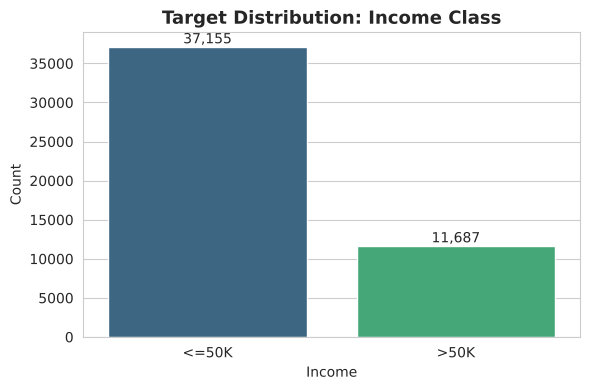

income
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64


In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='income', hue='income', palette='viridis', legend=False)
ax.set_title('Target Distribution: Income Class', fontsize=13, fontweight='bold')
ax.set_xlabel('Income')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

print(df['income'].value_counts(normalize=True).round(3))

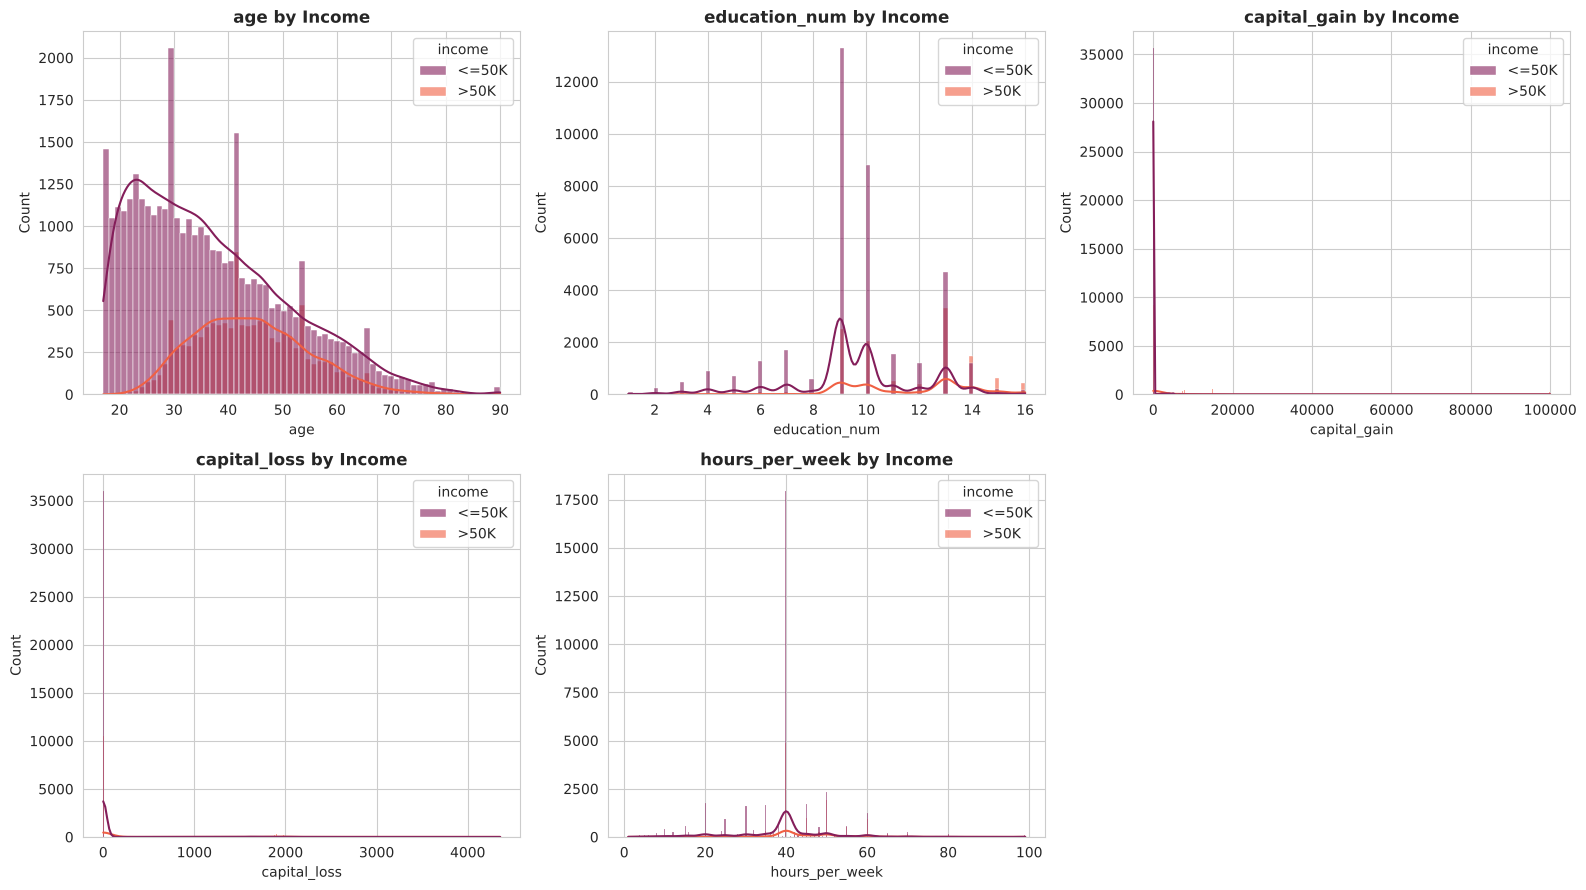

In [6]:
numeric_cols_raw = ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
palette = sns.color_palette('rocket', 2)

for i, col in enumerate(numeric_cols_raw):
    sns.histplot(data=df, x=col, hue='income', palette=palette, kde=True, ax=axes[i], alpha=0.6)
    axes[i].set_title(f'{col} by Income', fontweight='bold')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

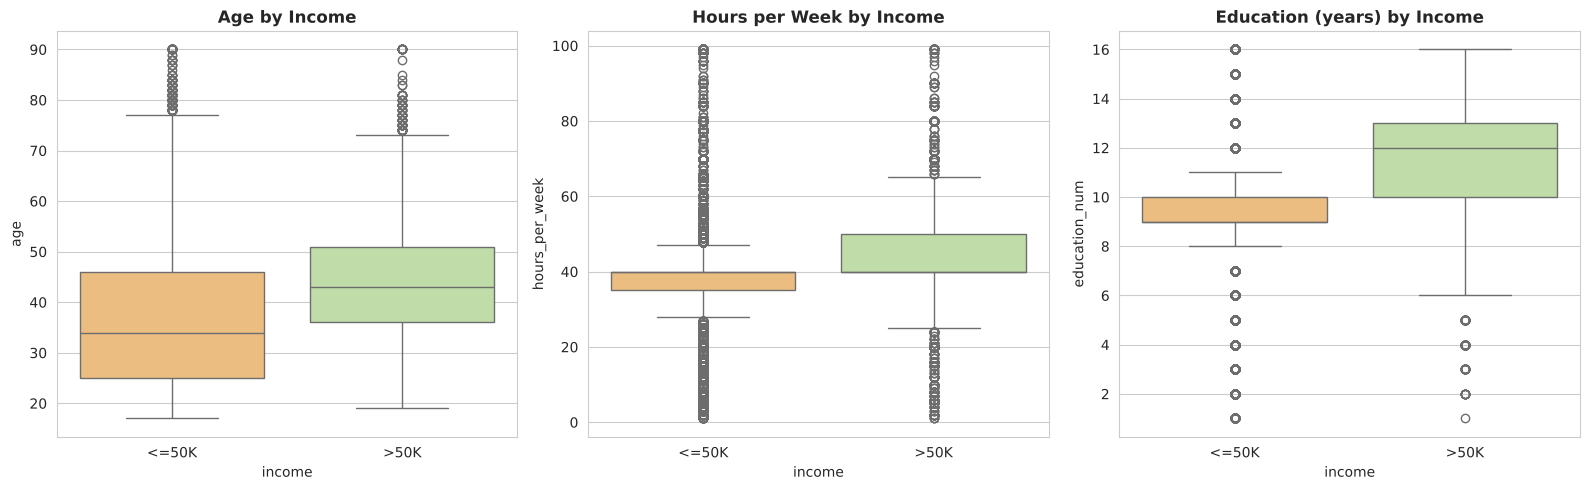

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x='income', y='age', hue='income', palette='Spectral', ax=axes[0], legend=False)
axes[0].set_title('Age by Income', fontweight='bold')

sns.boxplot(data=df, x='income', y='hours_per_week', hue='income', palette='Spectral', ax=axes[1], legend=False)
axes[1].set_title('Hours per Week by Income', fontweight='bold')

sns.boxplot(data=df, x='income', y='education_num', hue='income', palette='Spectral', ax=axes[2], legend=False)
axes[2].set_title('Education (years) by Income', fontweight='bold')

plt.tight_layout()
plt.show()

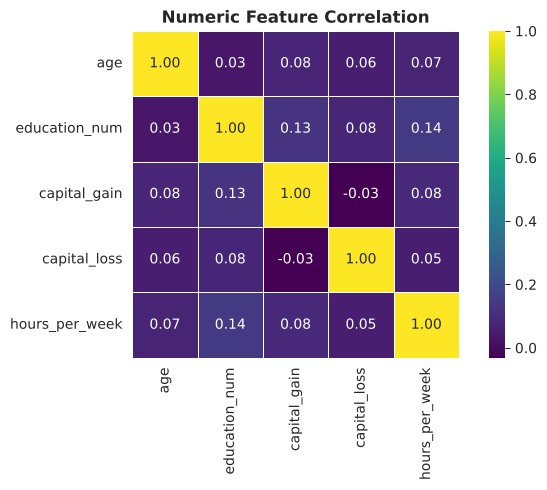

In [8]:
plt.figure(figsize=(7, 5))
corr = df[numeric_cols_raw].corr()
sns.heatmap(corr, annot=True, cmap='viridis', fmt='.2f', square=True, linewidths=0.5)
plt.title('Numeric Feature Correlation', fontweight='bold')
plt.tight_layout()
plt.show()

**EDA takeaways:**
- Classes are imbalanced (~76% ≤50K, ~24% >50K) — motivates using AUC/F1/MCC alongside accuracy.
- Higher earners skew toward more education years, more hours worked, and (unsurprisingly) higher age — all three show clear separation by income class.
- Numeric features aren't strongly correlated with each other, so no redundancy to prune there.
- `native_country` is dominated by United-States (~90%); the long tail of ~40 other countries has very few rows each.

## Section 3: Data Cleaning and Preprocessing

In [9]:
# fnlwgt is a census sampling weight, not predictive of income -> drop
# education is a redundant string version of education_num -> drop
df = df.drop(columns=['fnlwgt', 'education'])

# Collapse native_country: dominant US + long noisy tail of ~40 countries with
# very few rows each -> one-hotting all of them adds mostly noise columns.
df['native_country'] = np.where(df['native_country'] == 'United-States', 'United-States', 'Other')

# Drop rows with missing workclass/occupation (small %, no natural "unknown" category)
df = df.dropna(subset=['workclass', 'occupation'])

# Binary target
df['income'] = (df['income'] == '>50K').astype(int)

print(f"Shape after cleaning: {df.shape}")

Shape after cleaning: (46033, 13)


In [10]:
# Stratified subsample: keeps SVM training and Streamlit Cloud deployment fast,
# while staying ~12x over the assignment's 500-instance minimum.
SAMPLE_SIZE = 6000
df_sample, _ = train_test_split(df, train_size=SAMPLE_SIZE, stratify=df['income'], random_state=42)

numeric_cols = ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
categorical_cols = ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

X = df_sample[numeric_cols + categorical_cols]
y = df_sample['income']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

n_samples = df_sample.shape[0]
n_features = len(numeric_cols) + len(categorical_cols)
train_samples, test_samples = X_train.shape[0], X_test.shape[0]
train_test_ratio = round(train_samples / n_samples, 2)

print(f"Sampled: {n_samples} rows, {n_features} raw features")
print(f"Train: {train_samples}, Test: {test_samples}, split ratio: {train_test_ratio:.1%}")

Sampled: 6000 rows, 12 raw features
Train: 4800, Test: 1200, split ratio: 80.0%


In [11]:
# Held-out test split, in original (pre-encoding) feature form, for the Streamlit app.
# The app loads a saved pipeline (preprocessing + model bundled together) and scores
# this CSV directly -- no retraining happens in the app.
test_data = X_test.copy()
test_data['income'] = y_test.values
test_data.to_csv('test_data.csv', index=False)
print(f"test_data.csv written: {test_data.shape}")
display(test_data.head())

test_data.csv written: (1200, 13)


,age,education_num,capital_gain,capital_loss,hours_per_week,workclass,marital_status,occupation,relationship,race,sex,native_country,income
21518,61,10,0,0,25,Private,Divorced,Other-service,Not-in-family,White,Male,United-States,0
16297,46,9,0,0,40,Private,Married-civ-spouse,Craft-repair,Husband,White,Male,United-States,0
8028,47,9,0,0,32,Private,Divorced,Other-service,Own-child,White,Female,United-States,0
31004,28,9,0,0,40,Private,Married-civ-spouse,Transport-moving,Husband,White,Male,United-States,0
20584,67,13,0,0,30,Self-emp-not-inc,Married-civ-spouse,Sales,Husband,White,Male,United-States,0


## Section 4: Class Imbalance — Balance or Leave As-Is?

The target is ~75% `≤50K` vs ~25% `>50K`. This is a **moderate** imbalance (3:1), not a
severe one, so there are three options:

| Option | What it does | Verdict for this dataset |
|---|---|---|
| Leave as-is | Train on natural class ratio | Models favour the majority class → high accuracy, low recall on `>50K` |
| Resample (SMOTE / under-sampling) | Synthesise or discard rows to force 50:50 | Not needed at 3:1; SMOTE invents synthetic one-hot rows and adds a dependency (`imbalanced-learn`) to the deployed app; under-sampling throws away ~half the training data |
| **Cost-sensitive learning** (`class_weight='balanced'`) | Penalises mistakes on the minority class more during training — no rows added or removed | **Chosen**: same data, no extra dependency, and can be *tuned* — CV decides per model whether it helps |

Two rules are followed regardless of the option:
1. **The test set is never balanced** — it keeps the real-world 75/25 ratio so the reported metrics are honest.
2. **Accuracy is not the selection metric** — a model predicting `≤50K` for everyone already scores ~75%. Models are tuned on **F1** of the positive class, with AUC and MCC reported alongside.

Class weighting is put into each model's hyperparameter grid (`class_weight` for LR/DT/SVM,
`priors` for Naive Bayes; KNN has no weighting option), so cross-validation decides whether
balancing helps each model. The comparison is shown after tuning.

In [12]:
print("Class ratio in train :", y_train.value_counts(normalize=True).round(3).to_dict())
print("Class ratio in test  :", y_test.value_counts(normalize=True).round(3).to_dict())
print(f"Imbalance ratio (neg:pos) = {(y_train == 0).sum() / (y_train == 1).sum():.2f} : 1")
print(f"Accuracy of a 'always predict <=50K' baseline on test = {(y_test == 0).mean():.4f}")

Class ratio in train : {0: 0.752, 1: 0.248}
Class ratio in test  : {0: 0.752, 1: 0.248}
Imbalance ratio (neg:pos) = 3.03 : 1
Accuracy of a 'always predict <=50K' baseline on test = 0.7517


## Section 5: Hyperparameter Tuning and Training

Each model is wrapped in the same `preprocessor + classifier` pipeline, so every saved
`.joblib` file is self-contained: it accepts the raw feature columns directly. Because the
preprocessor sits **inside** the pipeline, scaling and encoding are re-fitted on each CV
training fold — no information leaks from validation folds.

`GridSearchCV` uses **5-fold stratified CV on the training set only** (the test set is
untouched until final evaluation), scores every combination on F1 / MCC / AUC / Accuracy /
Precision / Recall, and refits the best combination by **F1**.

| Model | Hyperparameters searched |
|---|---|
| Logistic Regression | `C` (regularisation strength), `class_weight` |
| Decision Tree | `max_depth`, `min_samples_leaf`, `criterion`, `class_weight` |
| KNN | `n_neighbors`, `weights`, `p` (Manhattan vs Euclidean) |
| Naive Bayes | `var_smoothing`, `priors` (natural vs 50/50) |
| SVM (RBF) | `C`, `gamma`, `class_weight` |

In [13]:
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_cols),
])

model_grids = {
    'Logistic Regression': (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {'model__C': [0.01, 0.1, 1, 10, 100],
         'model__class_weight': [None, 'balanced']}),
    'Decision Tree': (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'model__max_depth': [4, 6, 8, 10, 12, None],
         'model__min_samples_leaf': [1, 5, 10, 20],
         'model__criterion': ['gini', 'entropy'],
         'model__class_weight': [None, 'balanced']}),
    'KNN': (
        KNeighborsClassifier(),
        {'model__n_neighbors': [5, 11, 15, 21, 31, 41],
         'model__weights': ['uniform', 'distance'],
         'model__p': [1, 2]}),
    'Naive Bayes': (
        GaussianNB(),
        {'model__var_smoothing': np.logspace(-9, 0, 10),
         'model__priors': [None, [0.5, 0.5]]}),
    'Support Vector Machine': (
        SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
        {'model__C': [0.1, 1, 10],
         'model__gamma': ['scale', 0.01, 0.1],
         'model__class_weight': [None, 'balanced']}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1': 'f1', 'mcc': make_scorer(matthews_corrcoef), 'auc': 'roc_auc',
    'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
}
for name, (_, grid) in model_grids.items():
    n = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name:<24} {n:>3} combinations x 5 folds = {n * 5} fits")

Logistic Regression       10 combinations x 5 folds = 50 fits
Decision Tree             96 combinations x 5 folds = 480 fits
KNN                       24 combinations x 5 folds = 120 fits
Naive Bayes               20 combinations x 5 folds = 100 fits
Support Vector Machine    18 combinations x 5 folds = 90 fits


In [14]:
results = {}
fitted_pipelines = {}
best_params = {}
cv_tables = {}
roc_data = {}

for name, (clf, grid) in model_grids.items():
    search = GridSearchCV(
        Pipeline(steps=[('preprocess', preprocessor), ('model', clf)]),
        param_grid=grid, scoring=scoring, refit='f1', cv=cv, n_jobs=-1,
    )
    t0 = time.time()
    search.fit(X_train, y_train)
    search_time = time.time() - t0

    pipe = search.best_estimator_          # already refitted on the full training set
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_proba),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'MCC': matthews_corrcoef(y_test, y_pred),
        'CV F1': search.best_score_,
        'Tuning Time (s)': round(search_time, 1),
        'Refit Time (s)': round(search.refit_time_, 3),
    }
    fitted_pipelines[name] = pipe
    best_params[name] = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
    cv_tables[name] = pd.DataFrame(search.cv_results_)
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[name] = (fpr, tpr, results[name]['AUC'])

    print(f"✓ {name:<24} tuned in {search_time:5.1f}s | CV F1 {search.best_score_:.4f} "
          f"| test F1 {results[name]['F1']:.4f} | best: {best_params[name]}")

✓ Logistic Regression      tuned in   3.0s | CV F1 0.6865 | test F1 0.6833 | best: {'C': 100, 'class_weight': 'balanced'}


✓ Decision Tree            tuned in  14.1s | CV F1 0.6795 | test F1 0.6722 | best: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 20}


✓ KNN                      tuned in   9.7s | CV F1 0.6476 | test F1 0.6362 | best: {'n_neighbors': 21, 'p': 2, 'weights': 'uniform'}


✓ Naive Bayes              tuned in   2.6s | CV F1 0.6730 | test F1 0.6709 | best: {'priors': None, 'var_smoothing': np.float64(0.1)}


✓ Support Vector Machine   tuned in  86.3s | CV F1 0.6811 | test F1 0.6756 | best: {'C': 1, 'class_weight': 'balanced', 'gamma': 'scale'}


In [15]:
best_params_df = pd.DataFrame(
    {name: {'Best hyperparameters': ', '.join(f'{k}={v}' for k, v in p.items())}
     for name, p in best_params.items()}).T
display(best_params_df)

,Best hyperparameters
Logistic Regression,"C=100, class_weight=balanced"
Decision Tree,"class_weight=balanced, criterion=entropy, max_..."
KNN,"n_neighbors=21, p=2, weights=uniform"
Naive Bayes,"priors=None, var_smoothing=0.1"
Support Vector Machine,"C=1, class_weight=balanced, gamma=scale"


### Did balancing help? (cross-validation evidence)

For each model that supports class weighting, the best configuration *without* weighting
is compared with the best configuration *with* weighting, using the 5-fold CV scores
(training data only, so this does not peek at the test set).

CV Accuracy  CV AUC  \
Model                  Weighting                                   
Logistic Regression    balanced                   0.8117  0.9016   
                       none (natural ratio)       0.8473  0.9015   
Decision Tree          balanced                   0.8069  0.8854   
                       none (natural ratio)       0.8419  0.8724   
Naive Bayes            balanced                   0.7933  0.8881   
                       none (natural ratio)       0.8285  0.8881   
Support Vector Machine balanced                   0.8031  0.8996   
                       none (natural ratio)       0.8429  0.8838   

                                             CV Precision  CV Recall   CV F1  \
Model                  Weighting                                               
Logistic Regression    balanced                    0.5848     0.8312  0.6865   
                       none (natural ratio)        0.7361     0.5995  0.6608   
Decision Tree          balanced                    0.5776     0.8253  0.6795   
                       none (natural ratio)        0.7241     0.5886  0.6483   
Naive Bayes            balanced                    0.5561     0.8337  0.6670   
                       none (natural ratio)        0.6392     0.7112  0.6730   
Support Vector Machine balanced                    0.5695     0.8472  0.6811   
                       none (natural ratio)        0.7132     0.6146  0.6601   

                                             CV MCC  
Model                  Weighting                     
Logistic Regression    balanced              0.5754  
                       none (natural ratio)  0.5686  
Decision Tree          balanced              0.5654  
                       none (natural ratio)  0.5534  
Naive Bayes            balanced              0.5486  
                       none (natural ratio)  0.5589  
Support Vector Machine balanced              0.5691  
                       none (natural ratio)  0.5614

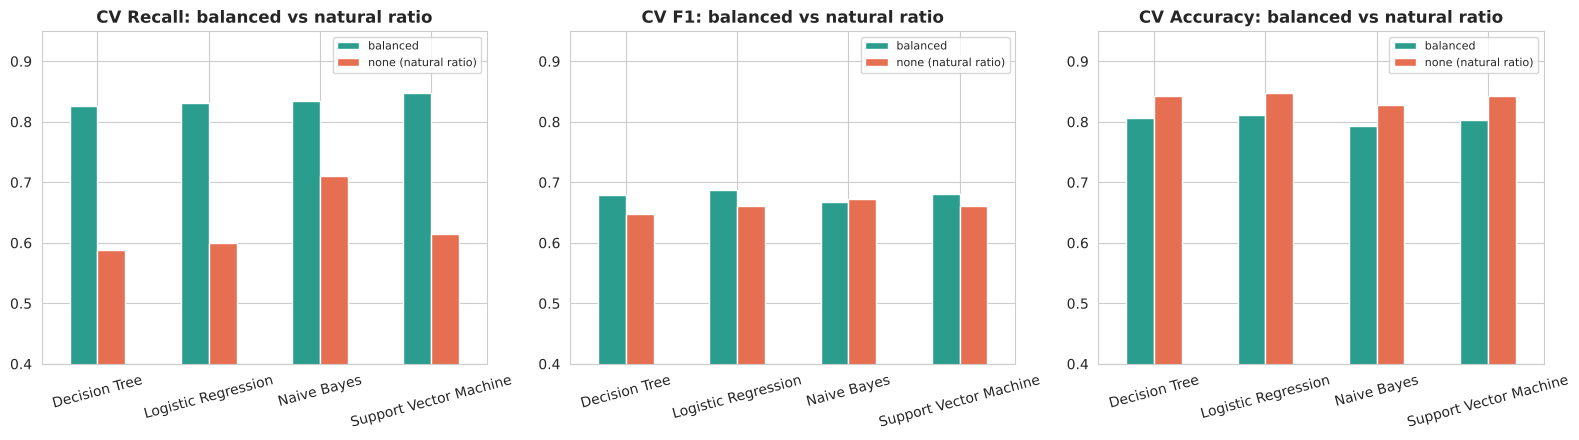

In [16]:
rows = []
for name, cvr in cv_tables.items():
    col = next((c for c in cvr.columns
                if c in ('param_model__class_weight', 'param_model__priors')), None)
    if col is None:
        continue   # KNN has no class-weighting option
    mode = cvr[col].apply(lambda v: 'balanced' if isinstance(v, (str, list)) else 'none (natural ratio)')
    for m, sub in cvr.groupby(mode):
        best = sub.loc[sub['mean_test_f1'].idxmax()]
        rows.append({'Model': name, 'Weighting': m,
                     **{k: best[f'mean_test_{s}'] for k, s in
                        [('CV Accuracy', 'accuracy'), ('CV AUC', 'auc'), ('CV Precision', 'precision'),
                         ('CV Recall', 'recall'), ('CV F1', 'f1'), ('CV MCC', 'mcc')]}})

balance_df = pd.DataFrame(rows).set_index(['Model', 'Weighting']).round(4)
display(balance_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, ['CV Recall', 'CV F1', 'CV Accuracy']):
    balance_df[metric].unstack().plot(kind='bar', ax=ax, color=['#2a9d8f', '#e76f51'], rot=15)
    ax.set_title(f'{metric}: balanced vs natural ratio', fontweight='bold')
    ax.set_xlabel(''); ax.set_ylim(0.4, 0.95); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

> **📌 NOTE:** The dataset itself was **not balanced**. The rows stay at the natural 75/25 ratio. The *training* was balanced through class weights, chosen per model by cross-validation.

**Imbalance verdict:**
- For **Logistic Regression, Decision Tree and SVM**, `class_weight='balanced'` raises recall on
  `>50K` from ~0.60 to ~0.83 and improves CV F1 by 2–3 points and MCC slightly — so CV selected it.
- **AUC barely moves** — weighting doesn't make a model better at *ranking* people; it shifts
  where the decision threshold falls, trading precision for recall.
- **Accuracy drops ~3–4 points** with balancing. This is expected and acceptable: accuracy on a
  75/25 target rewards predicting the majority class.
- For **Naive Bayes**, forcing 50/50 priors *hurts* — its probability estimates already push
  toward the positive class, so CV kept the natural priors.
- **Conclusion:** leave the data itself unbalanced (no resampling, test set at the true ratio)
  and let cost-sensitive class weighting be chosen per model by cross-validation.

## Section 6: Evaluation and Comparison (held-out test set)

In [17]:
metric_cols = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
results_df = pd.DataFrame(results).T
results_df[metric_cols + ['CV F1']] = results_df[metric_cols + ['CV F1']].astype(float).round(4)
display(results_df)

,Accuracy,AUC,Precision,Recall,F1,MCC,CV F1,Tuning Time (s),Refit Time (s)
Logistic Regression,0.8092,0.9008,0.5812,0.8289,0.6833,0.5705,0.6865,3.0,0.073
Decision Tree,0.8008,0.8917,0.5684,0.8221,0.6722,0.5547,0.6795,14.1,0.035
KNN,0.8342,0.8837,0.6988,0.5839,0.6362,0.5335,0.6476,9.7,0.021
Naive Bayes,0.8283,0.8919,0.6402,0.7047,0.6709,0.5563,0.6730,2.6,0.032
Support Vector Machine,0.7975,0.9041,0.5610,0.8490,0.6756,0.5615,0.6811,86.3,2.594


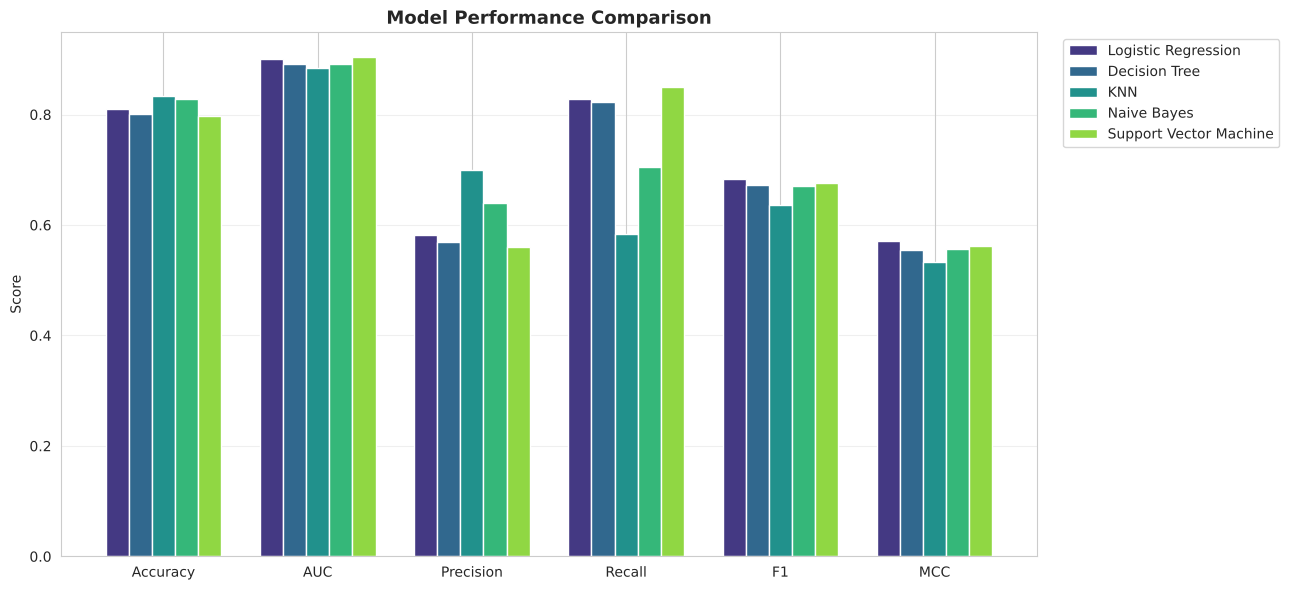

In [18]:
metric_cols = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
plot_df = results_df[metric_cols]

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(metric_cols))
width = 0.15
palette = sns.color_palette('viridis', len(plot_df))

for i, (name, row) in enumerate(plot_df.iterrows()):
    ax.bar(x + i * width, row.values, width, label=name, color=palette[i])

ax.set_xticks(x + width * (len(plot_df) - 1) / 2)
ax.set_xticklabels(metric_cols)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison', fontsize=13, fontweight='bold')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

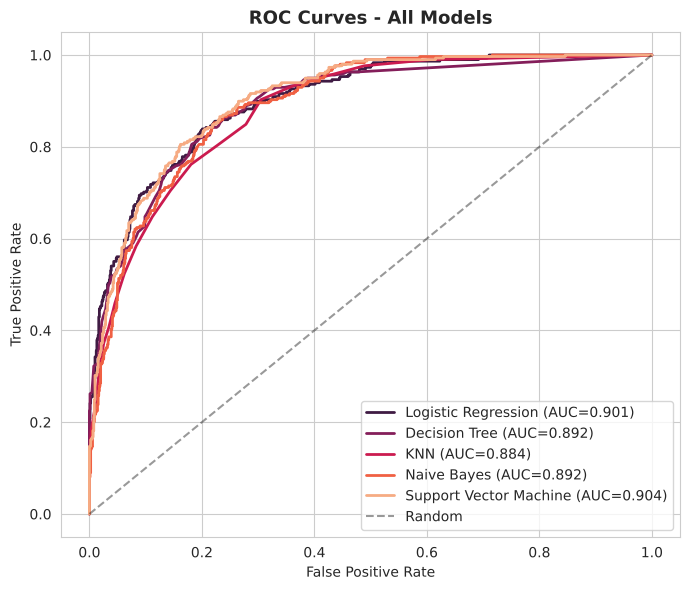

In [19]:
plt.figure(figsize=(7, 6))
palette = sns.color_palette('rocket', len(roc_data))
for i, (name, (fpr, tpr, auc)) in enumerate(roc_data.items()):
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=palette[i], linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Models', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

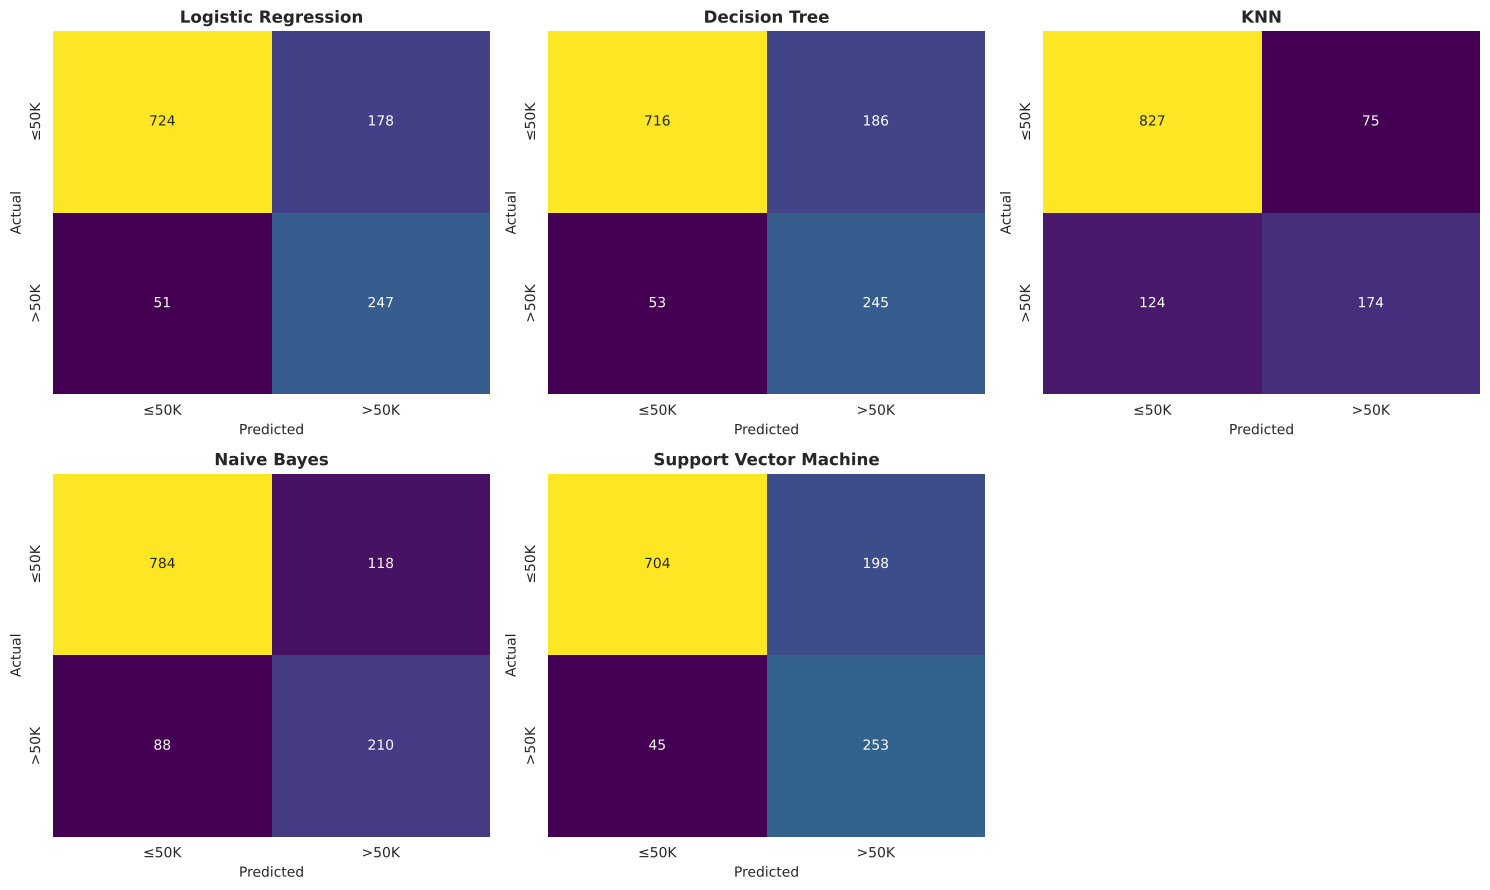

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, pipe) in enumerate(fitted_pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', ax=axes[i], cbar=False,
                xticklabels=['≤50K', '>50K'], yticklabels=['≤50K', '>50K'])
    axes[i].set_title(name, fontweight='bold')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

## Section 7: Save Models and Artifacts

In [21]:
import os
os.makedirs('model', exist_ok=True)

name_to_file = {
    'Logistic Regression': 'logistic_regression',
    'Decision Tree': 'decision_tree',
    'KNN': 'knn',
    'Naive Bayes': 'naive_bayes',
    'Support Vector Machine': 'svm',
}

for name, pipe in fitted_pipelines.items():
    fname = f"model/{name_to_file[name]}.joblib"
    joblib.dump(pipe, fname, compress=3)
    print(f"Saved {fname}  ({os.path.getsize(fname) / 1024:.0f} KB)")

results_df.to_csv('model/comparison_table.csv')
best_params_df.to_csv('model/best_hyperparameters.csv')
balance_df.to_csv('model/class_balance_cv.csv')
print("\nSaved model/comparison_table.csv, model/best_hyperparameters.csv, model/class_balance_cv.csv")

# Sanity check: reload a saved pipeline and score test_data.csv exactly as the app does
reloaded = joblib.load('model/logistic_regression.joblib')
td = pd.read_csv('test_data.csv')
print("Reload check — LR test F1:",
      round(f1_score(td['income'], reloaded.predict(td.drop(columns='income'))), 4))

Saved model/logistic_regression.joblib  (2 KB)
Saved model/decision_tree.joblib  (11 KB)
Saved model/knn.joblib  (92 KB)
Saved model/naive_bayes.joblib  (3 KB)
Saved model/svm.joblib  (50 KB)

Saved model/comparison_table.csv, model/best_hyperparameters.csv, model/class_balance_cv.csv
Reload check — LR test F1: 0.6833


## Section 8: Observations

| Model | Tuned hyperparameters | Observation |
|---|---|---|
| **Logistic Regression** | `C=100`, `class_weight='balanced'` | Best F1 (0.683) and MCC (0.571), and second-best AUC (0.901). Class weighting raised recall on `>50K` from 0.59 to 0.83. The tuned `C` is large, meaning little regularisation is needed: with only ~40 one-hot features and 4,800 rows the linear model is not overfitting. A linear boundary separates the classes about as well as the non-linear models do. |
| **Decision Tree** | `criterion='entropy'`, `max_depth=None`, `min_samples_leaf=20`, `class_weight='balanced'` | F1 0.672, close behind LR. CV preferred controlling overfitting with a minimum leaf size of 20 rather than a hard depth cap; larger leaves also give smoother probability estimates, which lifted AUC from 0.870 (untuned, depth 8) to 0.892. Still the most interpretable model. |
| **KNN** | `n_neighbors=21`, `weights='uniform'`, `p=2` | Highest accuracy (0.834) and precision (0.699) but the lowest recall (0.584), F1 (0.636), MCC and AUC. KNN has no class-weighting option, so with a 3:1 majority among its 21 neighbours it leans toward `≤50K`. Its top accuracy is a clear example of why accuracy is misleading on an imbalanced target. Distance is also diluted by the many binary one-hot columns. |
| **Naive Bayes** | `var_smoothing=0.1`, `priors=None` | The biggest gain from tuning: accuracy rose from 0.678 to 0.828 and F1 from 0.584 to 0.671. The default `var_smoothing=1e-9` gives near-zero variances on 0/1 one-hot columns, which produced extreme, overconfident probabilities and flagged almost everyone as `>50K`. Smoothing fixes that. Forcing 50/50 priors made CV scores worse, so the natural class ratio was kept. Its independence assumption is still violated, which caps its ceiling. |
| **Support Vector Machine** | `C=1`, `gamma='scale'`, `class_weight='balanced'` | Best AUC (0.904) and highest recall (0.849), so it ranks people best and misses the fewest high earners, but it has the lowest accuracy (0.798) and precision (0.561) at its default threshold. By far the most expensive: 86 s to tune and 2.6 s to refit, versus under 0.1 s for every other model. |
| **Overall winner** | **Logistic Regression** | It leads on F1 and MCC, the two threshold-based metrics that are fair under class imbalance, and is within 0.003 of the best AUC. It is also the fastest model to train and the easiest to explain. SVM is the alternative if ranking quality (AUC) matters most. |

### 🏆 Overall Ranking

| Rank | Model | F1 | MCC | AUC | Accuracy | In short |
|---|---|---|---|---|---|---|
| 🥇 1 | **Logistic Regression** | **0.683** | **0.571** | 0.901 | 0.809 | Best F1 & MCC, fastest, most explainable |
| 🥈 2 | Support Vector Machine | 0.676 | 0.562 | **0.904** | 0.798 | Best AUC & recall, but slowest |
| 🥉 3 | Decision Tree | 0.672 | 0.555 | 0.892 | 0.801 | Interpretable, slightly behind everywhere |
| 4 | Naive Bayes | 0.671 | 0.556 | 0.892 | 0.828 | Biggest gain from tuning (F1 +0.09) |
| 5 | KNN | 0.636 | 0.534 | 0.884 | **0.834** | Highest accuracy, but lowest recall & F1 |

*Ranked by F1, with MCC as tie-breaker: both are fair on the 75/25 imbalanced target, unlike accuracy.*

> **Winner: Logistic Regression.** It is best on the imbalance-fair metrics, within 0.003 AUC of SVM, and the fastest and simplest to explain.
